
# Grad-CAM para modelo ResNet50

Este notebook gera mapas **Grad-CAM** para o melhor modelo salvo via `ModelCheckpoint`.

O objetivo é visualizar as regiões das imagens que mais influenciaram as predições do modelo baseado em **ResNet50 + fine-tuning**.


## 1. Imports

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from PIL import Image
from matplotlib import cm
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications.resnet50 import preprocess_input



## 2. Configurações

Ajuste os caminhos abaixo caso o notebook esteja em outra pasta.


In [2]:

IMG_SIZE = (160, 160)
SEED = 42

IMAGES_DIR = "../data/images"
CSV_PATH = "../data/GroundTruth.csv"

# Altere este nome se o seu checkpoint tiver outro nome
MODEL_PATH = "../models/cnn_resnet/best_cnn_smote_2.keras"

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]

class_code = {label: code for code, label in enumerate(classes)}
class_name = {code: label for code, label in enumerate(classes)}

print(class_code)
print(class_name)


{'MEL': 0, 'NV': 1, 'BCC': 2, 'AKIEC': 3, 'BKL': 4, 'DF': 5, 'VASC': 6}
{0: 'MEL', 1: 'NV', 2: 'BCC', 3: 'AKIEC', 4: 'BKL', 5: 'DF', 6: 'VASC'}


## 3. Carregamento do melhor modelo

In [3]:

best_model = keras.models.load_model(MODEL_PATH)
best_model.summary()


Model: "cnn_smote_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 160, 160)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 160, 160)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 160, 160)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 160, 160,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 160, 160,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 5, 5,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7)         │        903 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,377,239 (92.99 MB)

 Trainable params: 263,175 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 526,352 (2.01 MB)


## 4. Preparação do conjunto de teste

Esta etapa utiliza o `GroundTruth.csv`, localiza os arquivos de imagem e separa os dados em treino, validação e teste no protocolo `70%`, `15%` e `15%`.

O conjunto de teste será usado apenas para gerar os exemplos do Grad-CAM.


In [4]:

def find_file(directory, base_name, extensions):
    for extension in extensions:
        path = os.path.join(directory, base_name + extension)
        if os.path.exists(path):
            return path
    return None


def prepare_metadata_with_image_paths(images_dir, metadata, class_code):
    rows = []

    for _, row in metadata.iterrows():
        image_name = str(row["image"])
        image_path = find_file(images_dir, image_name, [".jpg", ".jpeg", ".png"])

        if image_path is None:
            continue

        class_label = row[classes].idxmax()
        coded_label = class_code[class_label]

        rows.append({
            "image": image_name,
            "image_path": image_path,
            "label": coded_label,
            "class_name": class_label
        })

    return pd.DataFrame(rows)


metadata = pd.read_csv(CSV_PATH)

prepared_metadata = prepare_metadata_with_image_paths(
    IMAGES_DIR,
    metadata,
    class_code
)

print(prepared_metadata.head())
print("Quantidade de imagens encontradas:", len(prepared_metadata))
print(prepared_metadata["class_name"].value_counts())


          image                       image_path  label class_name
0  ISIC_0024306  ../data/images/ISIC_0024306.jpg      1         NV
1  ISIC_0024307  ../data/images/ISIC_0024307.jpg      1         NV
2  ISIC_0024308  ../data/images/ISIC_0024308.jpg      1         NV
3  ISIC_0024309  ../data/images/ISIC_0024309.jpg      1         NV
4  ISIC_0024310  ../data/images/ISIC_0024310.jpg      0        MEL
Quantidade de imagens encontradas: 10015
class_name
NV       6705
MEL      1113
BKL      1099
BCC       514
AKIEC     327
VASC      142
DF        115
Name: count, dtype: int64


In [6]:

# Separação treino/validação/teste: 70%, 15%, 15%
train_df, temp_df = train_test_split(
    prepared_metadata,
    test_size=0.30,
    random_state=SEED,
    stratify=prepared_metadata["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Treino:", len(train_df))
print("Validação:", len(val_df))
print("Teste:", len(test_df))

print("Distribuição no teste:")
print(test_df["class_name"].value_counts())


Treino: 7010
Validação: 1502
Teste: 1503
Distribuição no teste:
class_name
NV       1006
MEL       167
BKL       165
BCC        77
AKIEC      49
VASC       22
DF         17
Name: count, dtype: int64


## 5. Funções auxiliares para carregar imagens

In [7]:

def load_image_array(image_path, image_size=IMG_SIZE):
    image = keras.utils.load_img(
        image_path,
        target_size=image_size,
        color_mode="rgb"
    )
    image_array = keras.utils.img_to_array(image).astype("float32")
    return image_array


def predict_single_image(model, image_array):
    batch = np.expand_dims(image_array, axis=0)
    logits = model.predict(batch, verbose=0)
    pred_class = int(np.argmax(logits[0]))
    confidence = float(tf.nn.softmax(logits[0])[pred_class].numpy())
    return pred_class, confidence, logits



## 6. Localização da ResNet50 dentro do modelo

A última camada convolucional da ResNet50 geralmente é `conv5_block3_out`.


In [8]:

print("Camadas principais do modelo salvo:")

for i, layer in enumerate(best_model.layers):
    print(i, layer.name, type(layer))


Camadas principais do modelo salvo:
0 input_layer_1 <class 'keras.src.layers.core.input_layer.InputLayer'>
1 resnet50 <class 'keras.src.models.functional.Functional'>
2 global_average_pooling2d <class 'keras.src.layers.pooling.global_average_pooling2d.GlobalAveragePooling2D'>
3 dense <class 'keras.src.layers.core.dense.Dense'>
4 dropout <class 'keras.src.layers.regularization.dropout.Dropout'>
5 dense_1 <class 'keras.src.layers.core.dense.Dense'>


In [9]:

def get_resnet_base(model):
    for layer in model.layers:
        if "resnet" in layer.name.lower():
            return layer
    raise ValueError("Não foi possível encontrar a ResNet50 dentro do modelo.")


resnet_base = get_resnet_base(best_model)

print("Base encontrada:", resnet_base.name)
print("Últimas camadas da base ResNet50:")

for layer in resnet_base.layers[-10:]:
    print(layer.name, layer.output.shape)


Base encontrada: resnet50
Últimas camadas da base ResNet50:
conv5_block3_1_conv (None, 5, 5, 512)
conv5_block3_1_bn (None, 5, 5, 512)
conv5_block3_1_relu (None, 5, 5, 512)
conv5_block3_2_conv (None, 5, 5, 512)
conv5_block3_2_bn (None, 5, 5, 512)
conv5_block3_2_relu (None, 5, 5, 512)
conv5_block3_3_conv (None, 5, 5, 2048)
conv5_block3_3_bn (None, 5, 5, 2048)
conv5_block3_add (None, 5, 5, 2048)
conv5_block3_out (None, 5, 5, 2048)



## 7. Funções do Grad-CAM

Estas funções geram o mapa de ativação e sobrepõem o heatmap à imagem original.


In [10]:

def build_gradcam_models(model, last_conv_layer_name="conv5_block3_out"):
    resnet_base = get_resnet_base(model)
    last_conv_layer = resnet_base.get_layer(last_conv_layer_name)

    last_conv_model = keras.Model(
        inputs=resnet_base.input,
        outputs=[last_conv_layer.output, resnet_base.output],
        name="last_conv_model"
    )

    resnet_index = model.layers.index(resnet_base)

    classifier_input = keras.Input(shape=resnet_base.output.shape[1:])
    x = classifier_input

    for layer in model.layers[resnet_index + 1:]:
        if isinstance(layer, keras.layers.Dropout):
            x = layer(x, training=False)
        else:
            x = layer(x)

    classifier_model = keras.Model(
        inputs=classifier_input,
        outputs=x,
        name="classifier_model"
    )

    return last_conv_model, classifier_model


def make_gradcam_heatmap(
    image_array,
    model,
    last_conv_layer_name="conv5_block3_out",
    pred_index=None
):
    last_conv_model, classifier_model = build_gradcam_models(
        model,
        last_conv_layer_name=last_conv_layer_name
    )

    image_array = tf.cast(image_array, tf.float32)

    if len(image_array.shape) == 3:
        image_array = tf.expand_dims(image_array, axis=0)

    preprocessed_image = preprocess_input(image_array)

    with tf.GradientTape() as tape:
        last_conv_output, resnet_output = last_conv_model(preprocessed_image)
        tape.watch(last_conv_output)

        preds = classifier_model(resnet_output)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])

        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_output = last_conv_output[0]

    heatmap = last_conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    if max_value == 0:
        return heatmap.numpy()

    heatmap = heatmap / max_value
    return heatmap.numpy()


def overlay_gradcam(image_array, heatmap, alpha=0.40):
    image = np.array(image_array).astype("uint8")

    heatmap = np.uint8(255 * heatmap)

    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = Image.fromarray(np.uint8(jet_heatmap * 255))
    jet_heatmap = jet_heatmap.resize((image.shape[1], image.shape[0]))
    jet_heatmap = np.array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + image
    superimposed_img = np.uint8(superimposed_img)

    return superimposed_img


## 8. Teste do Grad-CAM em uma única imagem

/var/folders/w3/8wfk4l_97rbdm1dfkvx2cp6c0000gn/T/ipykernel_28061/3660215537.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


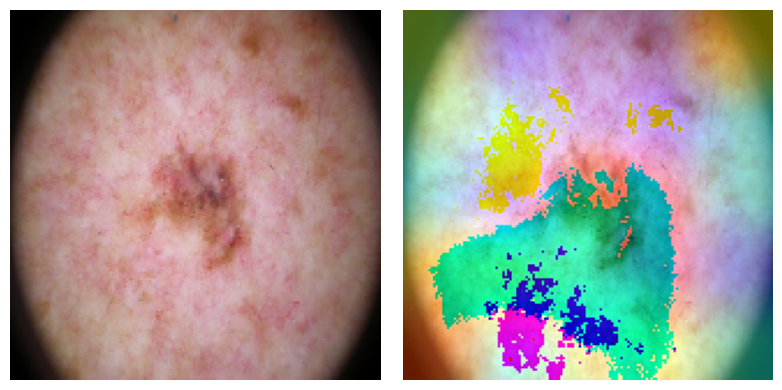

Imagem: ISIC_0033595
Classe real: MEL
Predição: MEL
Confiança: 0.5701996088027954
Figura salva como: gradcam_exemplo_unico.png


In [18]:

# Escolha uma classe específica para visualizar, ou use None para aleatório
TARGET_CLASS = "MEL"  # "MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC" ou None

if TARGET_CLASS is None:
    sample = test_df.sample(1, random_state=SEED).iloc[0]
else:
    sample = test_df[test_df["class_name"] == TARGET_CLASS].sample(
        1,
        random_state=SEED
    ).iloc[0]

image_array = load_image_array(sample["image_path"], IMG_SIZE)
pred_label, confidence, _ = predict_single_image(best_model, image_array)

heatmap = make_gradcam_heatmap(
    image_array,
    best_model,
    last_conv_layer_name="conv5_block3_out",
    pred_index=pred_label
)

gradcam_img = overlay_gradcam(image_array, heatmap, alpha=0.40)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array.astype("uint8"))
# plt.title(f"Original Real: {sample['class_name']}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gradcam_img)
# plt.title(f"Grad-CAM Pred: {class_name[pred_label]} ({confidence:.2f})")
plt.axis("off")

plt.tight_layout()
plt.savefig("../results/figures/cnn_resnet/gradcam_exemplo_unico.png", dpi=300, bbox_inches="tight")
plt.show()

print("Imagem:", sample["image"])
print("Classe real:", sample["class_name"])
print("Predição:", class_name[pred_label])
print("Confiança:", confidence)
print("Figura salva como: gradcam_exemplo_unico.png")



## 9. Coleta de predições no conjunto de teste

Esta célula percorre o conjunto de teste, calcula as predições e separa índices de acertos e erros.


In [14]:

def collect_test_predictions(model, dataframe, image_size=IMG_SIZE):
    images = []
    y_true = []
    y_pred = []
    confidences = []
    image_names = []

    for _, row in dataframe.iterrows():
        image_array = load_image_array(row["image_path"], image_size)
        pred_label, confidence, _ = predict_single_image(model, image_array)

        images.append(image_array)
        y_true.append(int(row["label"]))
        y_pred.append(int(pred_label))
        confidences.append(confidence)
        image_names.append(row["image"])

    return (
        np.array(images),
        np.array(y_true),
        np.array(y_pred),
        np.array(confidences),
        np.array(image_names)
    )


X_test_gradcam, y_true_gradcam, y_pred_gradcam, conf_gradcam, image_names_gradcam = collect_test_predictions(
    best_model,
    test_df,
    IMG_SIZE
)

correct_indices = np.where(y_true_gradcam == y_pred_gradcam)[0]
incorrect_indices = np.where(y_true_gradcam != y_pred_gradcam)[0]

print("Total:", len(y_true_gradcam))
print("Acertos:", len(correct_indices))
print("Erros:", len(incorrect_indices))


Total: 1503
Acertos: 1211
Erros: 292



## 10. Figura compacta para o artigo

Esta célula gera uma figura com 2 acertos e 2 erros. A ideia é usar essa imagem na seção de Resultados e Discussão.


/var/folders/w3/8wfk4l_97rbdm1dfkvx2cp6c0000gn/T/ipykernel_28061/3660215537.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


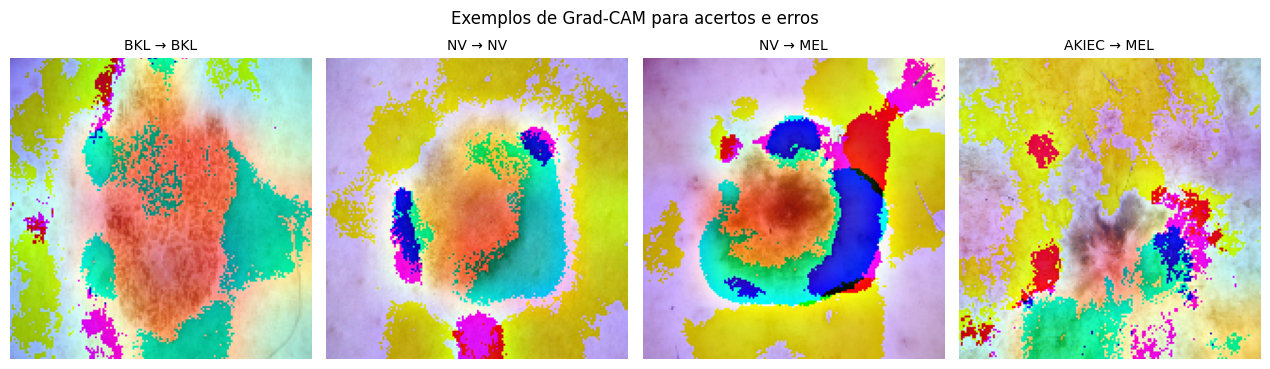

Figura salva como: gradcam_resnet50_artigo.png


In [15]:

def plot_gradcam_grid(
    model,
    images,
    y_true,
    y_pred,
    indices,
    class_name,
    save_path="gradcam_resnet50_artigo.png",
    last_conv_layer_name="conv5_block3_out",
    title="Grad-CAM - ResNet50"
):
    n = len(indices)

    plt.figure(figsize=(3.2 * n, 3.8))

    for plot_i, idx in enumerate(indices):
        image = images[idx]
        true_label = int(y_true[idx])
        pred_label = int(y_pred[idx])

        heatmap = make_gradcam_heatmap(
            image,
            model,
            last_conv_layer_name=last_conv_layer_name,
            pred_index=pred_label
        )

        gradcam_img = overlay_gradcam(image, heatmap, alpha=0.40)

        plt.subplot(1, n, plot_i + 1)
        plt.imshow(gradcam_img)
        plt.title(f"{class_name[true_label]} → {class_name[pred_label]}", fontsize=10)
        plt.axis("off")

    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Figura salva como: {save_path}")


selected_correct = correct_indices[:2]
selected_incorrect = incorrect_indices[:2]
selected_indices = np.concatenate([selected_correct, selected_incorrect])

plot_gradcam_grid(
    model=best_model,
    images=X_test_gradcam,
    y_true=y_true_gradcam,
    y_pred=y_pred_gradcam,
    indices=selected_indices,
    class_name=class_name,
    save_path="gradcam_resnet50_artigo.png",
    title="Exemplos de Grad-CAM para acertos e erros"
)


## 11. Figura separada para acertos

/var/folders/w3/8wfk4l_97rbdm1dfkvx2cp6c0000gn/T/ipykernel_28061/3660215537.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


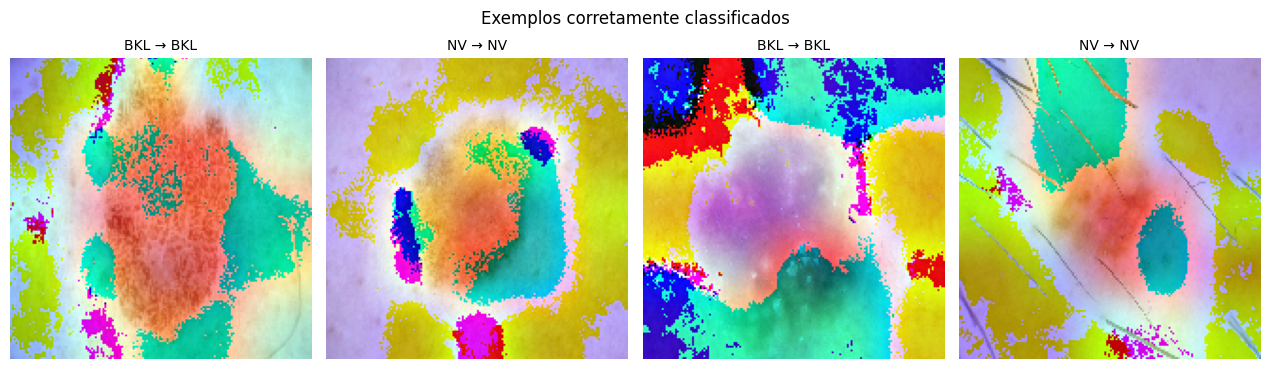

Figura salva como: gradcam_acertos.png


In [16]:

selected_correct = correct_indices[:4]

plot_gradcam_grid(
    model=best_model,
    images=X_test_gradcam,
    y_true=y_true_gradcam,
    y_pred=y_pred_gradcam,
    indices=selected_correct,
    class_name=class_name,
    save_path="gradcam_acertos.png",
    title="Exemplos corretamente classificados"
)


## 12. Figura separada para erros

/var/folders/w3/8wfk4l_97rbdm1dfkvx2cp6c0000gn/T/ipykernel_28061/3660215537.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


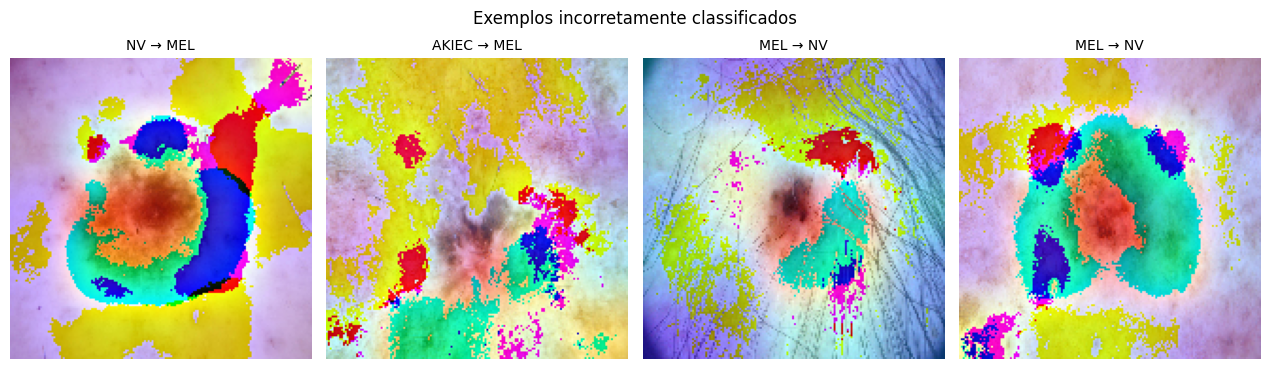

Figura salva como: gradcam_erros.png


In [17]:

selected_incorrect = incorrect_indices[:4]

plot_gradcam_grid(
    model=best_model,
    images=X_test_gradcam,
    y_true=y_true_gradcam,
    y_pred=y_pred_gradcam,
    indices=selected_incorrect,
    class_name=class_name,
    save_path="gradcam_erros.png",
    title="Exemplos incorretamente classificados"
)



## Texto sugerido para o artigo

**Metodologia:**  
Como análise complementar, foi utilizada a técnica Grad-CAM para visualizar as regiões das imagens que mais contribuíram para as predições do modelo baseado em ResNet50. Essa técnica gera mapas de ativação sobrepostos às imagens originais, permitindo observar se o modelo concentrou sua atenção na região da lesão ou em áreas externas à região de interesse.

**Resultados e discussão:**  
A análise visual por Grad-CAM indicou que, em algumas amostras corretamente classificadas, o modelo concentrou maior ativação sobre a região da lesão. Entretanto, em alguns casos incorretos, as ativações apareceram de forma mais dispersa ou associadas a regiões pouco discriminativas, sugerindo que o modelo ainda pode ser influenciado por padrões visuais não diretamente relacionados à lesão.

**Legenda:**  
Exemplos de mapas Grad-CAM gerados para o modelo baseado em ResNet50. As regiões em tons mais quentes indicam áreas com maior influência na predição do modelo.
